In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("CUDA device name:", torch.cuda.get_device_name(0))

In [ ]:
from pathlib import Path

BASE_DIR = Path(r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\train-yolov12")
DATA_DIR = Path(r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai")
yaml_path = DATA_DIR / "data.yaml"

print("BASE_DIR :", BASE_DIR)
print("DATA_DIR :", DATA_DIR)
print("YAML     :", yaml_path)



In [ ]:
with open(yaml_path, "r") as f:
    print(f.read())

In [ ]:
from ultralytics import YOLO
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

model = YOLO("yolov12n.pt")

results = model.train(
    data=str(yaml_path),
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20, # Early stopping patience (number of epochs with no improvement after which training will be stopped)
    name="yolov12n-cctv",
    project=str(BASE_DIR / "runs"),
    device=0,
    workers=0
)

In [1]:
from ultralytics import YOLO
import cv2
from IPython.display import display, Image
import os
import matplotlib.pyplot as plt

In [2]:
model_path = r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\train-yolov12\runs\yolov12n-cctv\weights\best.pt"

print("Model exists:", os.path.exists(model_path))



Model exists: True


In [3]:
image_path = r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\vlcsnap-2026-05-21-15h17m44s793.png"

print("Image exists:", os.path.exists(image_path))

Image exists: True


In [4]:
# Atur tampilan bbox
BBOX_LINE_WIDTH = 0.3      # semakin kecil, garis bbox semakin tipis
FONT_SIZE = 0           # ukuran font label
SHOW_FONT = True         # True = tampilkan label, False = sembunyikan label
SHOW_CONF = True         # True = tampilkan confidence, False = sembunyikan confidence

In [19]:
model = YOLO(model_path)

In [26]:
# ============================================================
# FOLDER INPUT
# ============================================================

image_folder_path = r"C:\Users\hardi\OneDrive\Pictures\vlc"

print("Folder exists:", os.path.exists(image_folder_path))


# ============================================================
# FOLDER OUTPUT
# ============================================================

output_folder = r"D:\1-Kuliah\SEKRIPSI\auto-label"

output_image_folder = os.path.join(
    output_folder,
    "images"
)

output_label_folder = os.path.join(
    output_folder,
    "labels"
)

os.makedirs(
    output_image_folder,
    exist_ok=True
)

os.makedirs(
    output_label_folder,
    exist_ok=True
)


# ============================================================
# MAPPING CLASS
# ============================================================

# Class model lama:
# 0 = bus
# 1 = mobil
# 2 = motor
# 3 = truk

# Class dataset baru:
# 0 = motor
# 1 = mobil
# 2 = truk
# 3 = bus

class_mapping = {
    0: 3,   # bus   -> bus
    1: 1,   # mobil -> mobil
    2: 0,   # motor -> motor
    3: 2    # truk  -> truk
}

new_class_names = [
    "motor",
    "mobil",
    "truk",
    "bus"
]


print("\nUrutan class baru:")

for class_id, class_name in enumerate(new_class_names):
    print(f"{class_id} = {class_name}")

Folder exists: True

Urutan class baru:
0 = motor
1 = mobil
2 = truk
3 = bus


In [27]:
# ============================================================
# DETEKSI SEMUA IMAGE
# ============================================================

results = model.predict(
    source=image_folder_path,
    conf=0.5,
    imgsz=640,
    save=False,
    verbose=False
)

print("Jumlah image diproses:", len(results))

Jumlah image diproses: 175


In [28]:
# ============================================================
# SIMPAN SEMUA IMAGE DAN LABEL
# ============================================================

for result in results:

    # Path image asli
    image_path = result.path

    # Nama file image
    image_filename = os.path.basename(image_path)

    # Nama file tanpa ekstensi
    image_name = os.path.splitext(
        image_filename
    )[0]


    # ========================================================
    # SIMPAN IMAGE ASLI
    # ========================================================

    output_image_path = os.path.join(
        output_image_folder,
        image_filename
    )

    shutil.copy2(
        image_path,
        output_image_path
    )


    # ========================================================
    # AMBIL HASIL DETEKSI
    # ========================================================

    boxes = (
        result.boxes.xywhn
        .cpu()
        .numpy()
    )

    classes = (
        result.boxes.cls
        .cpu()
        .numpy()
        .astype(int)
    )


    # ========================================================
    # PATH LABEL
    # ========================================================

    label_path = os.path.join(
        output_label_folder,
        image_name + ".txt"
    )


    # ========================================================
    # SIMPAN LABEL YOLO
    # ========================================================

    with open(label_path, "w") as f:

        for old_class_id, box in zip(
            classes,
            boxes
        ):

            # Mapping class lama -> class baru
            new_class_id = class_mapping[
                old_class_id
            ]

            x_center, y_center, width, height = box

            f.write(
                f"{new_class_id} "
                f"{x_center:.6f} "
                f"{y_center:.6f} "
                f"{width:.6f} "
                f"{height:.6f}\n"
            )


# ============================================================
# BUAT data.yaml
# ============================================================

yaml_path = os.path.join(
    output_folder,
    "data.yaml"
)

with open(yaml_path, "w") as f:

    f.write("names:\n")

    for class_id, class_name in enumerate(
        new_class_names
    ):
        f.write(
            f"  {class_id}: {class_name}\n"
        )

    f.write(
        f"\nnc: {len(new_class_names)}\n"
    )


# ============================================================
# HASIL
# ============================================================

print("Selesai!")
print("Jumlah image :", len(results))
print("Folder image :", output_image_folder)
print("Folder label :", output_label_folder)
print("data.yaml    :", yaml_path)

Selesai!
Jumlah image : 175
Folder image : D:\1-Kuliah\SEKRIPSI\auto-label\images
Folder label : D:\1-Kuliah\SEKRIPSI\auto-label\labels
data.yaml    : D:\1-Kuliah\SEKRIPSI\auto-label\data.yaml


## evaluasi

In [2]:
from ultralytics import YOLO
from pathlib import Path

# =====================================================
# 1. PATH
# =====================================================
BASE_DIR = Path(r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\train-yolov12")

MODEL_PATH = BASE_DIR / "runs" / "yolov12n-cctv" / "weights" / "best.pt"
DATA_PATH = Path(r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\data.yaml")


# =====================================================
# 2. LOAD MODEL
# =====================================================
model = YOLO(str(MODEL_PATH))

print(f"Model dimuat dari:\n{MODEL_PATH}")


# =====================================================
# 3. EVALUASI TEST SET
# =====================================================
metrics_test = model.val(
    data=str(DATA_PATH),
    split="test",
    imgsz=640,
    conf=0.001,
    batch=16,
    device=0,
    workers=0,
    plots=True,
    project=str(BASE_DIR / "runs"),
    name="testing"
)


Model dimuat dari:
D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\train-yolov12\runs\yolov12n-cctv\weights\best.pt
Ultralytics 8.4.52  Python-3.11.9 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
YOLOv12n summary (fused): 159 layers, 2,557,508 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access  (ping: 0.40.1 ms, read: 13.11.0 MB/s, size: 99.0 KB)
val: Scanning D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\test\labels.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.3it/s 3.0s1.2s
                   all         50       2545      0.927      0.851      0.905      0.723
                   bus         16         19      0.969      0.842      0.898      0.827
                 mobil         50       1134      0.939      0.883      0.956      0.745
                 motor         50       1302      0.908 

In [4]:

# Cetak Ringkasan Metrik Test
print("\n--- Ringkasan Metrik Test Set ---")
print(f"Precision : {metrics_test.results_dict['metrics/precision(B)']:.4f}")
print(f"Recall    : {metrics_test.results_dict['metrics/recall(B)']:.4f}")
print(f"mAP50     : {metrics_test.results_dict['metrics/mAP50(B)']:.4f}")
print(f"mAP50-95  : {metrics_test.results_dict['metrics/mAP50-95(B)']:.4f}")


--- Ringkasan Metrik Test Set ---
Precision : 0.9266
Recall    : 0.8507
mAP50     : 0.9051
mAP50-95  : 0.7232


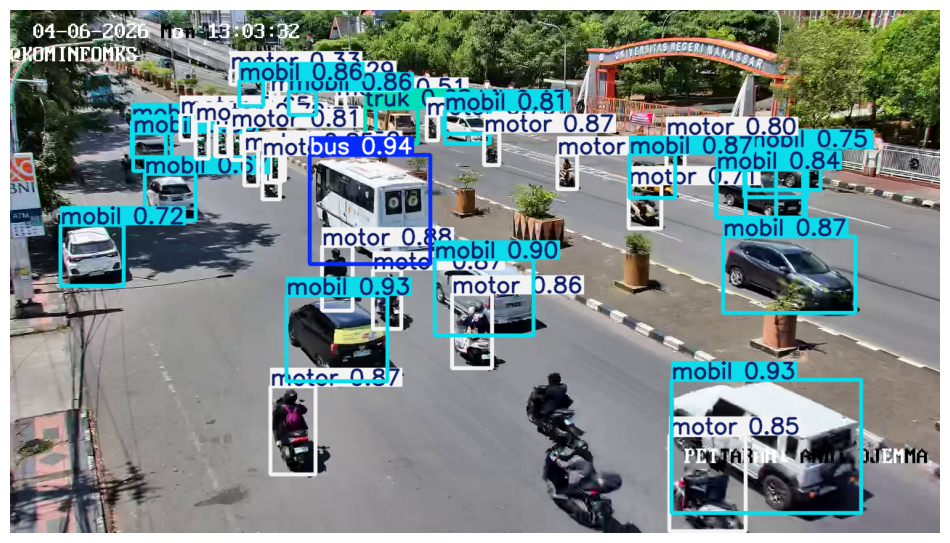

In [41]:
# Ambil gambar hasil prediksi
result_img = results[0].plot()

# Convert BGR ke RGB agar warna benar saat ditampilkan
result_img_rgb = cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB)

# Tampilkan langsung di notebook
plt.figure(figsize=(12, 8))
plt.imshow(result_img_rgb)
plt.axis("off")
plt.show()

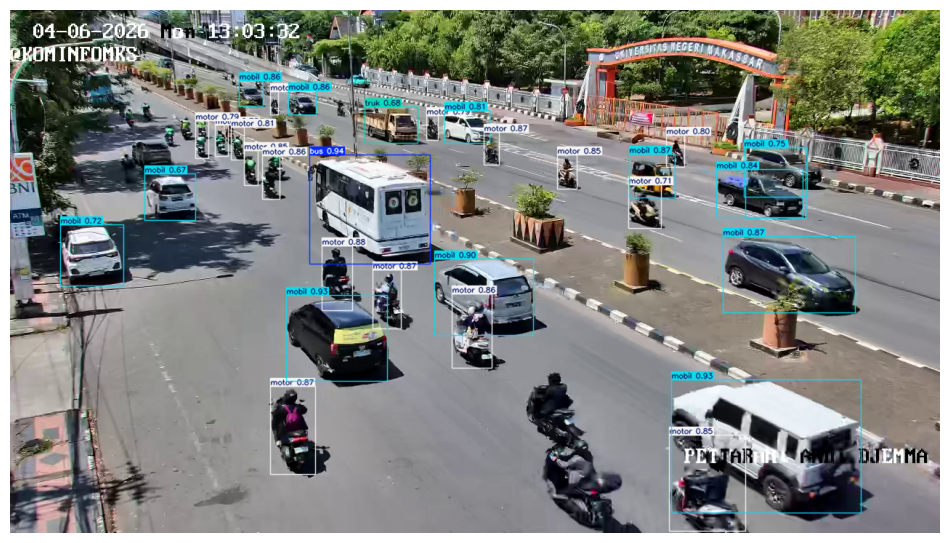

In [47]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import os

# =====================================================
# KONFIGURASI
# =====================================================
model_path = r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\train-yolov12\runs\yolov12n-cctv\weights\best.pt"
image_path = r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\vlcsnap-2026-05-21-15h17m44s793.png"

CONF_THRESHOLD = 0.65

# Atur tampilan bbox
BBOX_LINE_WIDTH = 1      # semakin kecil, garis bbox semakin tipis
FONT_SIZE = 8            # ukuran font label
SHOW_FONT = True         # True = tampilkan label, False = sembunyikan label
SHOW_CONF = True         # True = tampilkan confidence, False = sembunyikan confidence

# =====================================================
# LOAD MODEL
# =====================================================
model = YOLO(model_path)

# =====================================================
# PREDIKSI
# =====================================================
results = model.predict(
    source=image_path,
    conf=CONF_THRESHOLD,
    imgsz=640,
    verbose=False
)

# =====================================================
# PLOT HASIL
# =====================================================
result_img = results[0].plot(
    line_width=BBOX_LINE_WIDTH,
    font_size=FONT_SIZE,
    labels=SHOW_FONT,
    conf=SHOW_CONF if SHOW_FONT else False
)

# Convert BGR ke RGB
result_img_rgb = cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB)

# =====================================================
# TAMPILKAN
# =====================================================
plt.figure(figsize=(12, 8))
plt.imshow(result_img_rgb)
plt.axis("off")
plt.show()